In [5]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from utils.db import get_engine

df = pd.read_sql("SELECT * FROM marts.daily_features", get_engine(), parse_dates=["trade_date"])
df = df.dropna(subset=["ret", "spy_ret", "dgs10_chg_bp", "t10y2y_chg_bp"])

# zwroty w %, zmiany stóp w jednostkach po 10 pb, żeby współczynnik czytać jako
# "o ile % zmienia się zwrot przy ruchu 10Y o 10 pb"
df["ret_pct"] = df["ret"] * 100
df["spy_pct"] = df["spy_ret"] * 100
df["level_10bp"] = df["dgs10_chg_bp"] / 10
df["slope_10bp"] = df["t10y2y_chg_bp"] / 10
df["regime"] = np.where(df["trade_date"] < "2022-03-01", "2020-2022 (zero rates)", "2022+ (hikes)")

df.groupby("ticker").size()

ticker
AAPL    1703
AMC     1703
BAC     1703
DUK     1703
GME     1703
GS      1703
JPM     1703
MSFT    1703
NEE     1703
NVDA    1703
O       1703
dtype: int64

In [12]:
FORMULA = "ret_pct ~ spy_pct + level_10bp + slope_10bp"


def fit(data: pd.DataFrame) -> pd.DataFrame:
    model = smf.ols(FORMULA, data=data).fit(cov_type="HAC", cov_kwds={"maxlags": 5})
    ci = model.conf_int()

    return pd.DataFrame({
        "beta": model.params,
        "low": ci[0],
        "high": ci[1],
        "p_value": model.pvalues,
        "n": int(model.nobs),
    }).drop("Intercept")


full = pd.concat({t: fit(g) for t, g in df.groupby("ticker")}, names=["ticker", "term"])
by_regime = pd.concat(
    {(t, r): fit(g) for (t, r), g in df.groupby(["ticker", "regime"])},
    names=["ticker", "regime", "term"],
)

full.xs("level_10bp", level="term").sort_values("beta").round(3)

full.xs("slope_10bp", level="term").sort_values("beta").round(3)

,beta,low,high,p_value,n
ticker,,,,,
NVDA,-0.395,-0.734,-0.056,0.022,1703
AAPL,-0.058,-0.229,0.113,0.506,1703
GS,0.058,-0.166,0.282,0.610,1703
MSFT,0.066,-0.117,0.249,0.480,1703
JPM,0.095,-0.111,0.300,0.367,1703
NEE,0.132,-0.055,0.319,0.166,1703
BAC,0.178,-0.107,0.463,0.222,1703
DUK,0.290,0.108,0.471,0.002,1703
O,0.322,0.139,0.505,0.001,1703


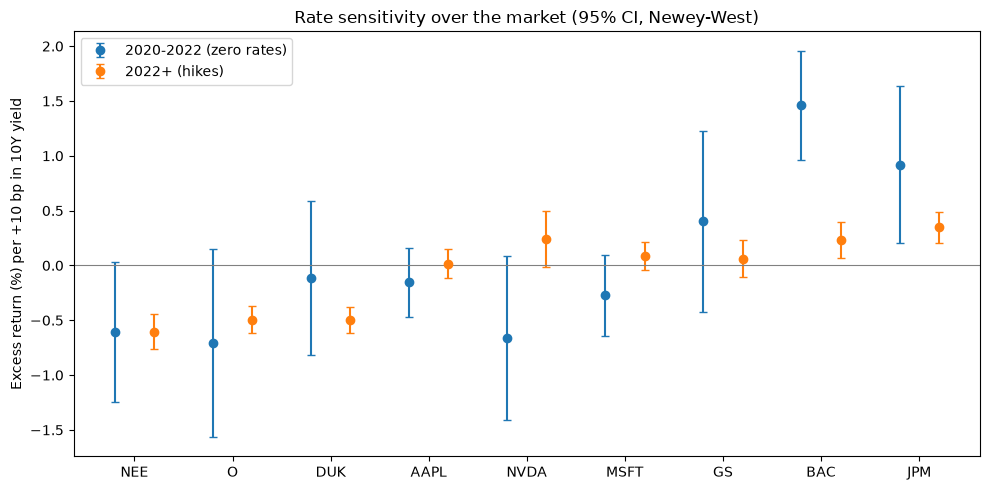

In [14]:
level = by_regime.xs("level_10bp", level="term").reset_index()
order = full.xs("level_10bp", level="term").sort_values("beta").index
order = order[~order.isin(["GME", "AMC"])]

fig, ax = plt.subplots(figsize=(10, 5))
offsets = {"2020-2022 (zero rates)": -0.2, "2022+ (hikes)": 0.2}

for regime, offset in offsets.items():
    part = level[level["regime"] == regime].set_index("ticker").loc[order]
    x = np.arange(len(order)) + offset
    ax.errorbar(x, part["beta"], yerr=[part["beta"] - part["low"], part["high"] - part["beta"]],
                fmt="o", capsize=3, label=regime)

ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(np.arange(len(order)), order)
ax.set_ylabel("Excess return (%) per +10 bp in 10Y yield")
ax.set_title("Rate sensitivity over the market (95% CI, Newey-West)")
ax.legend()
plt.tight_layout()
plt.savefig("../docs/rate_sensitivity.png", dpi=150)
plt.show()